<a href="https://colab.research.google.com/github/divyasethu0506-droid/divya/blob/main/Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [5]:
import zipfile
import io
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), 'r') as zip_ref:
    zip_ref.extractall('/content/car_dataset')

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [6]:
import glob

csv_files = glob.glob('/content/car_dataset/**/*.csv', recursive=True)

print("Available CSV files:")
for file in csv_files:
    print(file)

Available CSV files:
/content/car_dataset/Car details v3.csv
/content/car_dataset/CAR DETAILS FROM CAR DEKHO.csv
/content/car_dataset/car details v4.csv
/content/car_dataset/car data.csv


In [7]:
df = pd.read_csv('/content/car_dataset/car data.csv')

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [8]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Dataset shape before cleaning

print("\nBefore Cleaning:")
print(df.shape)

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Rows:
2

Before Cleaning:
(301, 9)


In [9]:
# Remove duplicate rows

df = df.drop_duplicates()

# Remove extra spaces from column names

df.columns = df.columns.str.strip()

# Clean categorical columns

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].str.strip().str.title()

# Fill missing numerical values

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Data Cleaning Completed Successfully!")

print(df.isnull().sum())

Data Cleaning Completed Successfully!
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [10]:
display(df.head())

print("Final Dataset Shape:", df.shape)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,Ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,Sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,Ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,Wagon R,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,Swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


Final Dataset Shape: (299, 9)


In [11]:
# Calculate Car Age

df['Car_Age'] = 2026 - df['Year']

# Extract Brand from Car Name

df['Brand'] = df['Car_Name'].str.split().str[0]

# Display updated dataset

display(df[['Car_Name', 'Year', 'Car_Age', 'Brand']].head(10))

print("Feature Engineering Completed Successfully!")

,Car_Name,Year,Car_Age,Brand
0,Ritz,2014,12,Ritz
1,Sx4,2013,13,Sx4
2,Ciaz,2017,9,Ciaz
3,Wagon R,2011,15,Wagon
4,Swift,2014,12,Swift
5,Vitara Brezza,2018,8,Vitara
6,Ciaz,2015,11,Ciaz
7,S Cross,2015,11,S
8,Ciaz,2016,10,Ciaz
9,Ciaz,2015,11,Ciaz


Feature Engineering Completed Successfully!


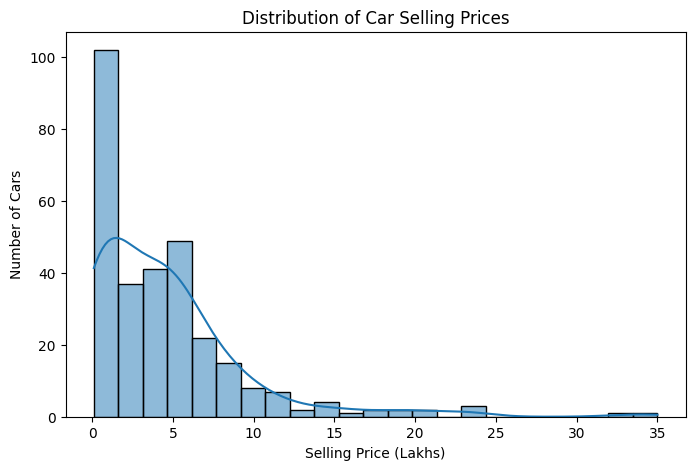

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df['Selling_Price'], kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price (Lakhs)')
plt.ylabel('Number of Cars')

plt.show()

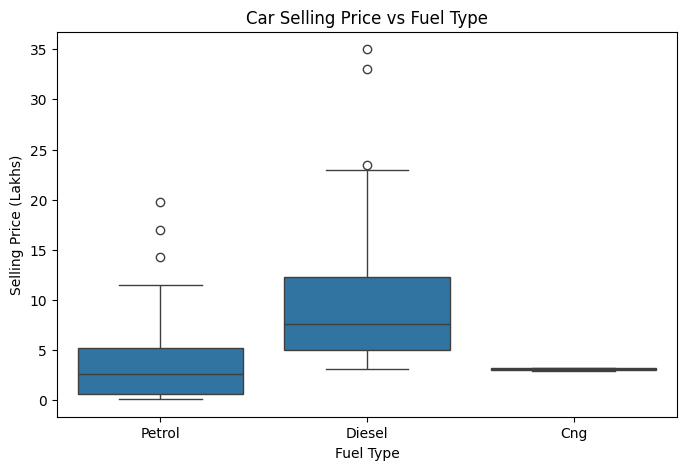

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')

plt.title('Car Selling Price vs Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (Lakhs)')

plt.show()

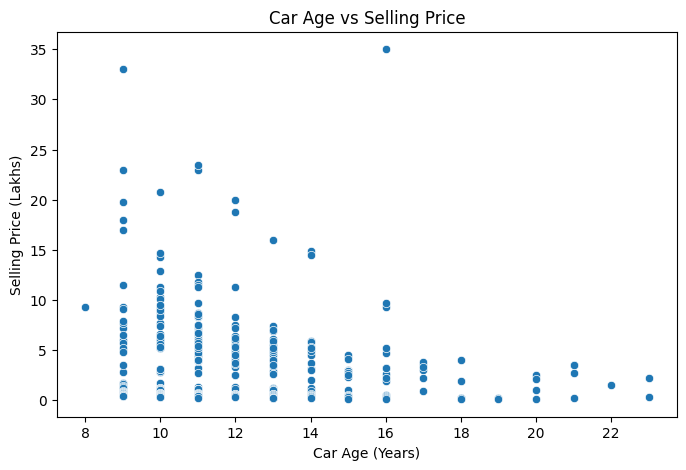

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='Car_Age', y='Selling_Price')

plt.title('Car Age vs Selling Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price (Lakhs)')

plt.show()

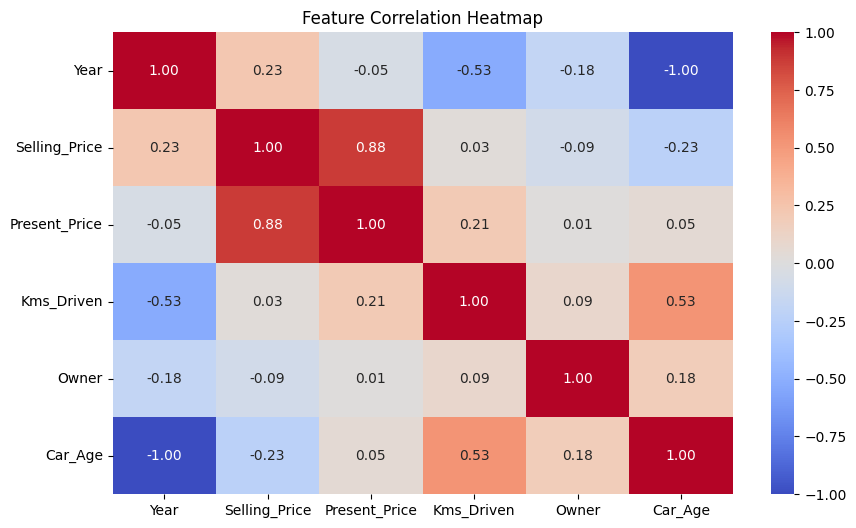

In [16]:
plt.figure(figsize=(10,6))

numeric_df = df.select_dtypes(include='number')

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Feature Correlation Heatmap')

plt.show()

In [17]:
# Convert categorical values into numerical values

df_encoded = pd.get_dummies(
    df,
    columns=['Fuel_Type', 'Seller_Type', 'Transmission', 'Brand'],
    dtype=int
)

print("Encoding Completed Successfully!")

display(df_encoded.head())

Encoding Completed Successfully!


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Cng,Fuel_Type_Diesel,Fuel_Type_Petrol,...,Brand_Suzuki,Brand_Swift,Brand_Sx4,Brand_Tvs,Brand_Um,Brand_Verna,Brand_Vitara,Brand_Wagon,Brand_Xcent,Brand_Yamaha
0,Ritz,2014,3.35,5.59,27000,0,12,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,Sx4,2013,4.75,9.54,43000,0,13,0,1,0,...,0,0,1,0,0,0,0,0,0,0
2,Ciaz,2017,7.25,9.85,6900,0,9,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,Wagon R,2011,2.85,4.15,5200,0,15,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,Swift,2014,4.60,6.87,42450,0,12,0,1,0,...,0,1,0,0,0,0,0,0,0,0


In [18]:
# Select input features

X = df_encoded.drop(
    ['Selling_Price', 'Car_Name', 'Year'],
    axis=1
)

# Select target variable

y = df_encoded['Selling_Price']

print("Features selected successfully!")
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

Features selected successfully!
X Shape: (299, 55)
Y Shape: (299,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train Test Split Completed!")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Train Test Split Completed!
Training Data: (239, 55)
Testing Data: (60, 55)


In [20]:
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create model

lr_model = LinearRegression()

# Train model

lr_model.fit(X_train, y_train)

# Predict car prices

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [21]:
# Import Random Forest

from sklearn.ensemble import RandomForestRegressor

# Create model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model

rf_model.fit(X_train, y_train)

# Predict car prices

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Linear Regression Evaluation

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Random Forest Evaluation

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Display Results

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.474063,2.795791,0.696723
1,Random Forest,1.318685,3.215378,0.598861


In [23]:
# Select the best model based on R2 Score

if rf_r2 > lr_r2:
    best_model = rf_model
    best_predictions = rf_predictions
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_predictions = lr_predictions
    best_model_name = "Linear Regression"

print("Best Performing Model:", best_model_name)

Best Performing Model: Linear Regression


In [24]:
if best_model_name == "Random Forest":

    importance = pd.Series(
        rf_model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False)

    plt.figure(figsize=(10,6))

    importance.head(10).plot(kind='bar')

    plt.title("Top 10 Important Features")
    plt.xlabel("Features")
    plt.ylabel("Importance")

    plt.show()

else:
    print("Linear Regression selected as best model.")
    print("Feature importance chart is not available for this model.")

Linear Regression selected as best model.
Feature importance chart is not available for this model.


In [25]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': best_predictions
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,8.99,8.372708
1,8.35,7.213103
2,0.45,1.761517
3,7.45,6.736249
4,5.25,11.529642
5,5.25,4.763967
6,5.85,8.693444
7,1.15,1.825844
8,9.25,8.310072
9,0.38,-0.716339


## Conclusion

In this project, a Car Price Prediction model was developed using Machine Learning.

The Vehicle Dataset from CarDekho was used to predict used car selling prices.

Data cleaning, feature engineering, data visualization and categorical encoding were performed.

Two regression algorithms, Linear Regression and Random Forest Regressor, were trained and evaluated using MAE, RMSE and R² Score.

The model with the better R² Score was selected as the best-performing model.

This project demonstrates how Machine Learning can help predict used car prices based on different car features.